# Cointegration Engine

### Summary Statistics

[*********************100%***********************]  2 of 2 completed

Ticker           R_t_XOM        R_t_CVX
mean        8.934205e-04   8.223495e-04
std dev     1.467664e-02   1.437222e-02
skewness   -4.377310e-01  -7.338908e-01
kurtosis    1.646859e+00   4.044906e+00
JB p-value  2.308882e-24  1.541953e-126


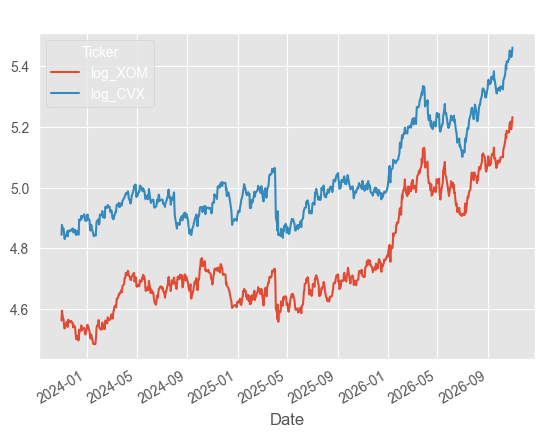

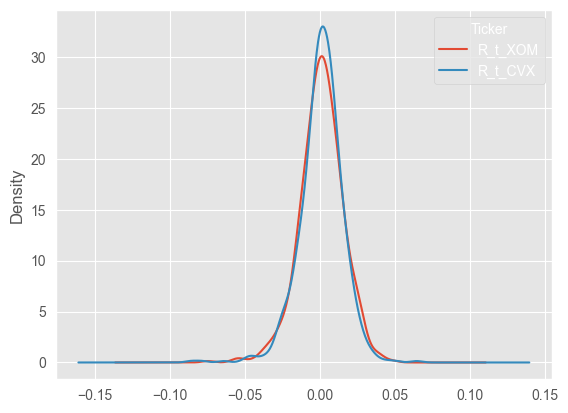

Text(0.5, 1.0, 'Hedge Ratio OLS Geometry')

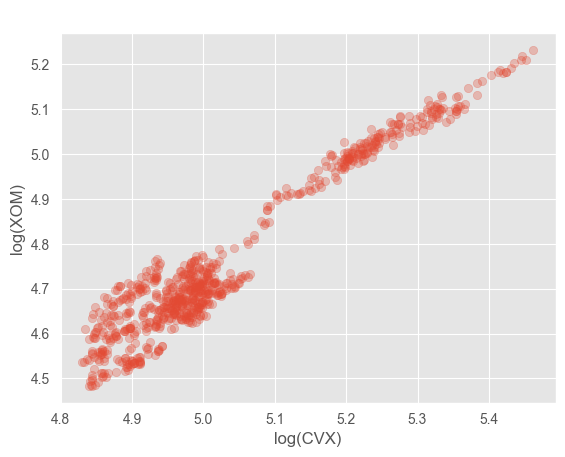

In [10]:
import pandas as pd
import numpy as np
import yfinance as yf
from scipy import stats as sp_stats
import matplotlib.pyplot as plt

np.random.seed(1234)
%matplotlib inline
plt.style.use('ggplot')

raw_data = yf.download(['XOM', 'CVX'], start='2023-11-01', end='2026-11-01')

df = raw_data['Close'].dropna().sort_index()

# Log prices
df['log_XOM'] = np.log(df['XOM'])
df['log_CVX'] = np.log(df['CVX'])
target_cols = ['log_XOM', 'log_CVX']

# Daily returns
df['R_t_XOM'] = np.log(df['XOM']).diff()
df['R_t_CVX'] = np.log(df['CVX']).diff()
target_cols_diff = ['R_t_XOM', 'R_t_CVX']

def compute_stats(series):
    return pd.Series({
        'mean': series.mean(), # daily mean drift
        'std dev': series.std(), # daily volatility
        'skewness': sp_stats.skew(series.dropna()),
        'kurtosis': sp_stats.kurtosis(series.dropna()),
        'JB p-value': sp_stats.jarque_bera(series.dropna())[1] # Jarque-Bera test
    })

stats = df[target_cols_diff].apply(compute_stats)
print(stats)

df[['log_XOM', 'log_CVX']].plot(title="Log Price Trajectories (Non-Stationary Regimes)")
plt.show()

df[['R_t_XOM', 'R_t_CVX']].dropna().plot(kind='kde')
plt.show()

plt.scatter(df['log_CVX'], df['log_XOM'], alpha=0.3)
plt.xlabel("log(CVX)")
plt.ylabel("log(XOM)")
plt.title("Hedge Ratio OLS Geometry")

### Visualizations
1. The average value of the daily returns (mean) for each of the tickers is $r_t \approx 0.0009$ for XOM, which implies that it has drifted up $e^{0.000934205} - 1 \approx 0.0009$ or just +0.09% a day or 22.6% a year. <br>
    While CVX corresponds to $r_t \approx 0.0008$ or +0.08% a day or 20.1% a year. <br>
2. The standard deviation represent the width of the bell with $1.5%$ for XOM and $1.4%$ for CVX. <br>
3. Skewness measures the asymmetry of the distribution around its mean. In our case, both series are slightly negatively skewed. Downside shocks are more common than upside drift.
4. Kurtosis measures the "tailedness" of the distribution. Both our series exhibit positive kurtosis, indicating a leptokurtic distribution.
5. Lastly, we can safely reject our $H_0$ with $p<0.05$ for the null hypothesis that the two series are normally distributed.

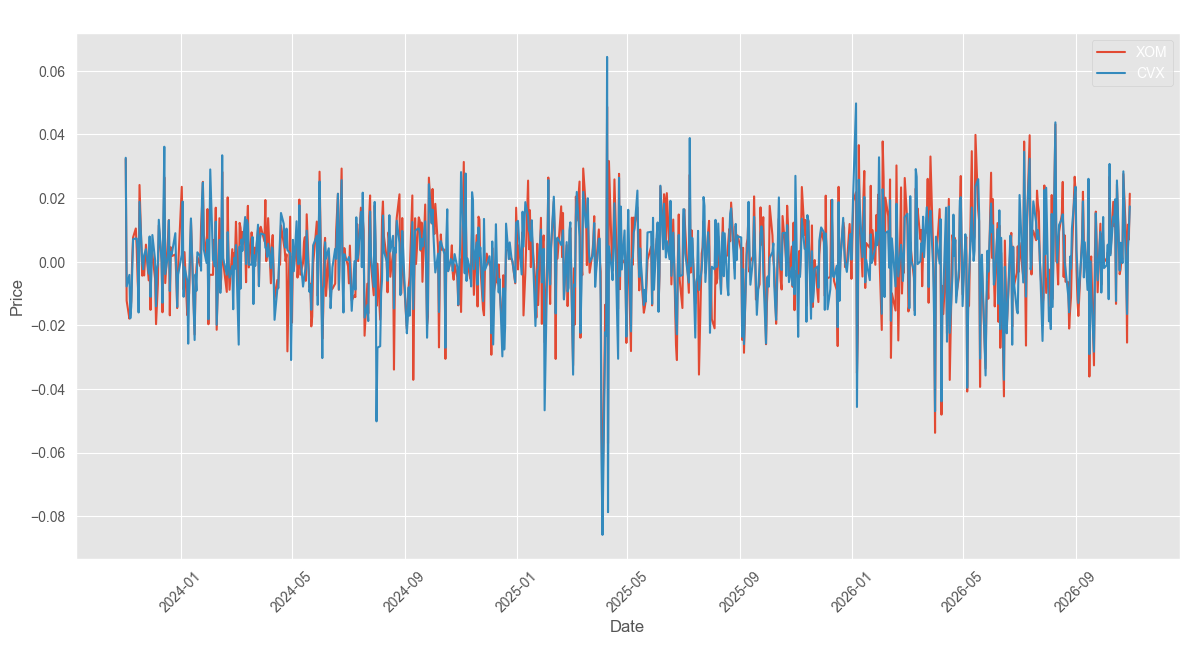

In [11]:
plt.figure(figsize=(12, 6))
plt.plot(df['R_t_XOM'])
plt.plot(df['R_t_CVX'])
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend(['XOM', 'CVX'])
plt.grid(True)
plt.tight_layout()
plt.xticks(rotation=45)
plt.title('XOM and CVX from 2023 to 2026')
plt.show()

### Augmented Dickey-Fuller Tests on log-prices
We perform the ADF test with $H_0$ that the two series have a unit root or possess non-stationarity. We expect the fail to reject the null hypothesis as we need the log-prices to be non-stationary in order to perform cointegration tests later. We must prove that both series are $I(1)$. As a result, we indeed fail to reject the null hypothesis.

### Augmented Dickey-Fuller Tests on log-returns
Our second ADF test consists of confirming whether the log-returns are weakly stationary $I(0)$. This formally proves that both series are of $I(1)$ and not of $+I(2)$ which is a requisite for cointegration. We expect to reject the null hypothesis as the log-returns are stationary and are of order 1 of integration. As a result, we do reject. Hence, we have formally established the prerequisites for Engle-Granger Two-Step Cointegration Test.


In [12]:
from statsmodels.tsa.stattools import adfuller

# Function to perform Augmented Dickey-Fuller test on log-prices
def perform_adf(series):
    result = adfuller(series.dropna())
    print('ADF Stat: %f' % result[0], ', p-value: %f' % result[1])

adf = df[target_cols].apply(perform_adf)
print(adf)

# perform Augmented Dickey-Fuller test on log-returns
adf_diff = df[target_cols_diff].apply(perform_adf)
print(adf_diff)

ADF Stat: 0.184194 , p-value: 0.971361
ADF Stat: 0.003520 , p-value: 0.958822
Ticker
log_XOM    None
log_CVX    None
dtype: object
ADF Stat: -27.374887 , p-value: 0.000000
ADF Stat: -26.477135 , p-value: 0.000000
Ticker
R_t_XOM    None
R_t_CVX    None
dtype: object


### Cointergration Test
We ran a cointegration test on the log-prices using **coint** with $H_0$ that our series are cointegrated. However, we **fail to reject at 5% with a p-value of 0.67**. To successfully reject the null hypothesis at 5% we need a critical value of at least -3.349. In conclusion, although ExxonMobil(XOM) and Chevron(CVX) look like they move together from our first plot and have a clear correlation. They are not cointegrated, in other words their linear spread wanders away like a random walk without circling back to a level/mean. The residuals $\varepsilon_t$ form a non-stationary random walk without mean-reverting properties. We are forced to pivot to another pair. Our choice falls on ETF's of Australia(EWA) and Canada(EWC), two commodity-exporting economies.

In [13]:
from statsmodels.tsa.stattools import coint
# Train/Test split avoiding look-ahead bias
split_idx = int(len(df) * 0.6)

train_df = df.iloc[:split_idx]
test_df = df.iloc[split_idx:]

# run engle-granger test
coint_stat, p_value, crit_values = coint(train_df['log_XOM'], train_df['log_CVX'])
print(f"Cointegrated Test Stat: {coint_stat:.4f}\np-value: {p_value:.4f}\nCritical values (1%, 5%, 10%): {crit_values}")

Cointegrated Test Stat: -1.7128
p-value: 0.6710
Critical values (1%, 5%, 10%): [-3.92094312 -3.34974169 -3.05388832]


### Visualisations
Our new data is nearly identical, alike the previous data, we reject normality.

[*********************100%***********************]  2 of 2 completed

Ticker        R_t_EWA        R_t_EWC
mean         0.000583   9.226458e-04
std dev      0.011621   9.395866e-03
skewness    -0.185250  -1.898095e-01
kurtosis    10.478366   4.593232e+00
JB p-value   0.000000  4.607922e-145


<Axes: ylabel='Density'>

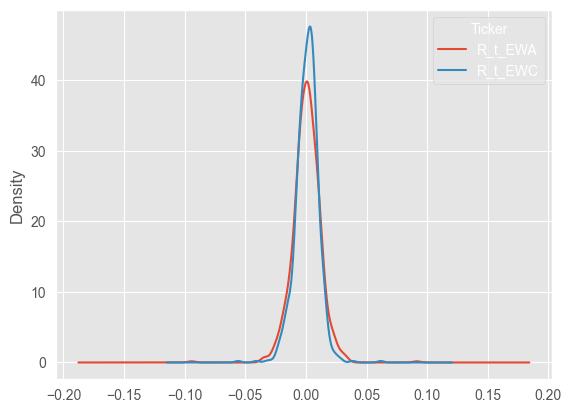

In [14]:
raw_data = yf.download(['EWA', 'EWC'], start='2023-11-01', end='2026-11-01')
df = raw_data['Close'].dropna().sort_index()

# Log prices
df['log_EWA'] = np.log(df['EWA'])
df['log_EWC'] = np.log(df['EWC'])
target_cols = ['log_EWA', 'log_EWC']

# Daily returns
df['R_t_EWA'] = df['log_EWA'].diff()
df['R_t_EWC'] = df['log_EWC'].diff()
target_cols_diff = ['R_t_EWA', 'R_t_EWC']

stats = df[target_cols_diff].apply(compute_stats)

print(stats)

df[target_cols_diff].plot(kind = 'kde')

### ADF
As expected, our data is I(1). Firstly, we fail to reject our null hypothesis for the ADF on log-prices.

In [15]:
# Perform Augmented Dickey-Fuller test on log-prices
adf = df[target_cols].apply(perform_adf)
adf

# Perform Augmented Dickey-Fuller test on log-returns
adf_diff = df[target_cols_diff].apply(perform_adf)
adf_diff


ADF Stat: -1.787701 , p-value: 0.386585
ADF Stat: -0.826345 , p-value: 0.811261
ADF Stat: -17.324412 , p-value: 0.000000
ADF Stat: -18.031391 , p-value: 0.000000


Ticker
R_t_EWA    None
R_t_EWC    None
dtype: object

In [16]:
split_idx = int(len(df) * 0.6)

train_df = df.iloc[:split_idx]
test_df = df.iloc[split_idx:]

coint_stat, p_value, crit_values = coint(train_df['log_EWA'], train_df['log_EWC'])
print(f"Stat: {coint_stat:.4f}, p-value: {p_value:.4f}, critical_values: {crit_values}")

Stat: -2.5204, p-value: 0.2702, critical_values: [-3.92094312 -3.34974169 -3.05388832]


### Analysis of 4 New Series
I have learned from my mistakes and decided to evaluate various pairs of financial assets. Out of the 4 pairs, 2 were cointegrated. Both are of order $I(1)$ and non-stationary, hence both main requisites for cointegration were satisfied. Mathematically, let $X_t \sim I(1)$ and $Y_t \sim I(1)$, they are cointegrated if there is some coefficient $\beta$ such that the residual spread is stationary: $$Z_t = Y_t - \beta X_t \sim I(0)$$

In [20]:
screen_pairs = [
    ('GOOGL', 'GOOG'),
    ('GDX', 'GLD'),
    ('XLE', 'XOM'),
    ('SPY', 'IVV')
]

def perform_adf(series):
    adf_stat, p_val, _, _, _, _ = adfuller(series)
    return p_val

for ticker_a, ticker_b in screen_pairs:
    raw_data = yf.download([ticker_a, ticker_b], start='2021-11-01', end='2026-11-01', progress=False)['Close']
    clean = raw_data[[ticker_a, ticker_b]].dropna().sort_index()
    split = int(len(clean) * 0.60)
    train = clean.iloc[:split]

    clean[f'log_{ticker_a}'] = np.log(clean[ticker_a])
    clean[f'log_{ticker_b}'] = np.log(clean[ticker_b])

    target_cols = [f'log_{ticker_a}', f'log_{ticker_b}']
    adf = clean[target_cols].apply(perform_adf)
    print(f"ADF Test on log-prices: [{ticker_a}-{ticker_b}] | p-values: {ticker_a}={adf.iloc[0]:.4e} | {ticker_b}={adf.iloc[1]:.4e}")
    adf_diff = clean[target_cols].diff().dropna().apply(perform_adf)
    print(f"ADF Test of Daily returns: [{ticker_a}-{ticker_b}] | p-values: {ticker_a}={adf_diff.iloc[0]:.4e} | {ticker_b}={adf_diff.iloc[1]:.4e}")

    y_a = np.log(clean[ticker_a])
    y_b = np.log(clean[ticker_b])

    stat, val, crit = coint(y_a, y_b)
    status = 'Yes (Cointegrated)' if val < 0.05 else 'No'
    print(f"[{ticker_a}-{ticker_b}]: Statistic: {stat:.4f} | p-val: {val:.4f} | critical-values: {crit} | cointegrated: {status}\n")


ADF Test on log-prices: [GOOGL-GOOG] | p-values: GOOGL=8.9773e-01 | GOOG=8.9475e-01
ADF Test of Daily returns: [GOOGL-GOOG] | p-values: GOOGL=0.0000e+00 | GOOG=0.0000e+00
[GOOGL-GOOG]: Statistic: -3.3687 | p-val: 0.0459 | critical-values: [-3.90519489 -3.34100683 -3.04783387] | cointegrated: Yes (Cointegrated)

ADF Test on log-prices: [GDX-GLD] | p-values: GDX=8.8045e-01 | GLD=8.9958e-01
ADF Test of Daily returns: [GDX-GLD] | p-values: GDX=1.1715e-28 | GLD=0.0000e+00
[GDX-GLD]: Statistic: -2.5890 | p-val: 0.2413 | critical-values: [-3.90519489 -3.34100683 -3.04783387] | cointegrated: No

ADF Test on log-prices: [XLE-XOM] | p-values: XLE=6.7421e-01 | XOM=6.6193e-01
ADF Test of Daily returns: [XLE-XOM] | p-values: XLE=0.0000e+00 | XOM=0.0000e+00
[XLE-XOM]: Statistic: -3.1559 | p-val: 0.0776 | critical-values: [-3.90519489 -3.34100683 -3.04783387] | cointegrated: No

ADF Test on log-prices: [SPY-IVV] | p-values: SPY=9.5170e-01 | IVV=9.5360e-01
ADF Test of Daily returns: [SPY-IVV] | p-valu